<a href="https://colab.research.google.com/github/nguyenkyvi/Machine_Learning/blob/main/Lab08-K_Means/_Lab8K_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
from sklearn.cluster import KMeans

P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]


def k_means(X, tam, so_vong_toi_da=10):
    """K-Means don gian: gan diem vao tam gan nhat roi doi tam."""
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán: khoảng cách từ mỗi điểm tới mỗi tâm
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")
        # Bước dời tâm: trung bình các điểm trong mỗi cụm
        tam_moi = np.array([X[nhan == k].mean(axis=0)
                            for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan


# Khởi tạo cố ý tệ: hai tâm là A và B, nằm sát nhau
tam, nhan = k_means(P, P[[0, 1]].copy())
print()

# Tính inertia: tổng bình phương khoảng cách tới tâm cụm của mình
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")

# So với scikit-learn, cho cùng tâm ban đầu
km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250
Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


In [4]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

# Tâm cụm đang ở thang đã chuẩn hoá, đổi ngược về đơn vị gốc để đọc
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                   columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print()
print(f"Inertia: {km.inertia_:.2f}")
print()

# Khách mới: chuẩn hoá bằng đúng bộ chuẩn hoá cũ rồi tìm tâm gần nhất
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0],
                    "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]},"
          f" chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    38.2      18.8           50.1
std      9.7       9.7           27.0
min     18.0       3.0            6.0
25%     32.0       9.9           22.0
50%     39.0      17.2           49.0
75%     46.0      29.0           78.0
max     62.0      35.5           98.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0      17.4           49.6        61     40.7
1      30.3           83.3        39     33.1
2       9.1           18.2        40     45.8
3       7.6           79.9        35     25.1
4      30.5           20.6        35     44.2

Inertia: 23.10

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 1
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 3


In [5]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print(" K    inertia   giam so voi K-1   silhouette")
truoc = None
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    # Silhouette cần ít nhất hai cụm
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f"  {k:2d}   {km.inertia_:7.1f}   {giam:>15s}   {sil:>10s}")
    truoc = km.inertia_

 K    inertia   giam so voi K-1   silhouette
   1     420.0                               
   2     248.1             171.9        0.414
   3     150.8              97.3        0.526
   4      73.0              77.8        0.620
   5      23.1              49.9        0.724
   6      19.7               3.4        0.616
   7      18.3               1.4        0.535
   8      16.8               1.5        0.475
   9      15.3               1.6        0.410
  10      13.9               1.4        0.404


In [7]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: thu nhập ghi bằng nghìn đồng, không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000         # đổi lại triệu đồng để dễ đọc
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")
print()

# Bẫy 2: mỗi lần chỉ khởi tạo ngẫu nhiên một lần
ket = []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1,
                random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print(" ", ket[:10])
print(" ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}")
print()

# Bẫy 3: cụm không tròn, dữ liệu hai vầng trăng
tr = pd.read_csv("data/hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan == tr["nhan"]).mean()
# Số thứ tự cụm có thể ngược với nhãn thật, nên lấy cách khớp tốt hơn
print(f"Bay 3: hai vang trang, ty le khop nhan that "
      f"{max(khop, 1 - khop):.4f}")

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  6.1,  58.6)
  (  9.9,  40.7)
  ( 17.7,  49.5)
  ( 27.9,  54.4)
  ( 32.0,  53.1)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.1, 23.1, 23.1, 23.1, 23.1, 23.1, 23.1, 23.1, 23.1, 71.2]
  [71.3, 71.3, 71.5, 72.6, 86.7, 87.4, 118.4, 118.6, 118.6, 118.6]
  Voi n_init=10: inertia 23.1

Bay 3: hai vang trang, ty le khop nhan that 0.7500


In [8]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

anh = load_sample_image("china.jpg")         # ảnh có sẵn trong scikit-learn
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0            # mỗi dòng là một điểm ảnh RGB
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau")
print()

# Học trên 5000 điểm ảnh rút ngẫu nhiên cho nhanh, rồi gán cho mọi điểm
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

print("  K   so bit moi diem   nho hon   sai lech trung binh")
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f" {k:2d}        {bit}            {24 / bit:4.1f} lan"
          f"      {sai:5.2f} muc sang")

Anh 427 x 640, co 273280 diem anh, 96615 mau

  K   so bit moi diem   nho hon   sai lech trung binh
  4        2            12.0 lan      17.41 muc sang
 16        4             6.0 lan       7.97 muc sang
 64        6             4.0 lan       4.54 muc sang


Bài Tập

BÀi 1

In [9]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

def silhouette_mot_diem(X, nhan, i):
    """Tra ve (a, b, s) cua diem thu i."""
    kc = np.sqrt(((X - X[i]) ** 2).sum(axis=1))      # khoang cach tu diem i toi moi diem
    cung = (nhan == nhan[i])
    cung[i] = False                                   # khong tinh chinh no
    a = kc[cung].mean() if cung.any() else 0.0
    b = min(kc[nhan == c].mean() for c in np.unique(nhan) if c != nhan[i])
    s = (b - a) / max(a, b)
    return a, b, s

df = pd.read_csv("data/khach_hang.csv")
sc = StandardScaler().fit(df[["thu_nhap", "diem_chi_tieu"]])
Xs = sc.transform(df[["thu_nhap", "diem_chi_tieu"]])
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
nhan = km.labels_

kq = np.array([silhouette_mot_diem(Xs, nhan, i) for i in range(len(Xs))])
print(f"Silhouette tu tinh trung binh : {kq[:, 2].mean():.4f}")
print(f"silhouette_score cua sklearn  : {silhouette_score(Xs, nhan):.4f}")

i = int(kq[:, 2].argmin())
goc = df.loc[i, ["thu_nhap", "diem_chi_tieu"]]
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=["thu_nhap", "diem_chi_tieu"]).round(1)
print(f"\nKhach co s nho nhat: so {i}, thu nhap {goc['thu_nhap']}, chi tieu {goc['diem_chi_tieu']}")
print(f"  a = {kq[i,0]:.3f}, b = {kq[i,1]:.3f}, s = {kq[i,2]:.3f}, thuoc cum {nhan[i]}")
print("Tam cac cum (don vi goc):")
print(tam.to_string())

Silhouette tu tinh trung binh : 0.7238
silhouette_score cua sklearn  : 0.7238

Khach co s nho nhat: so 53, thu nhap 9.4, chi tieu 53.0
  a = 0.880, b = 1.043, s = 0.156, thuoc cum 0
Tam cac cum (don vi goc):
   thu_nhap  diem_chi_tieu
0      17.4           49.6
1      30.3           83.3
2       9.1           18.2
3       7.6           79.9
4      30.5           20.6


Bài 2

In [10]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
cot = ["tuoi", "thu_nhap", "diem_chi_tieu"]
sc = StandardScaler().fit(df[cot])
Xs = sc.transform(df[cot])

print(" K  silhouette")
ds = {}
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    ds[k] = silhouette_score(Xs, km.labels_)
    print(f" {k:2d}  {ds[k]:.3f}")
k_tot = max(ds, key=ds.get)
print(f"\nK tot nhat theo silhouette: {k_tot} ({ds[k_tot]:.3f})")

km = KMeans(n_clusters=k_tot, n_init=10, random_state=0).fit(Xs)
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=cot)
tam["so_khach"] = pd.Series(km.labels_).value_counts().sort_index()
print("Tam cum (don vi goc):")
print(tam.round(1).sort_values("thu_nhap").to_string())

 K  silhouette
  2  0.379
  3  0.439
  4  0.481
  5  0.512
  6  0.472
  7  0.481
  8  0.459
  9  0.446
 10  0.425

K tot nhat theo silhouette: 5 (0.512)
Tam cum (don vi goc):
   tuoi  thu_nhap  diem_chi_tieu  so_khach
4  24.4       7.6           79.9        34
3  46.0       9.3           18.9        41
0  40.6      17.3           50.1        61
2  33.1      30.3           83.3        39
1  44.2      30.5           20.6        35


Bài 3

In [11]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs).inertia_
print(f"Inertia tot nhat (n_init=10): {tot:.1f}")

for init in ["random", "k-means++"]:
    ket = [KMeans(n_clusters=5, init=init, n_init=1, random_state=rs).fit(Xs).inertia_
           for rs in range(50)]
    dat = sum(round(v, 1) == round(tot, 1) for v in ket)
    print(f"{init:10s}: dat {tot:.1f} {dat}/50 lan, inertia te nhat {max(ket):.1f}")

Inertia tot nhat (n_init=10): 23.1
random    : dat 23.1 25/50 lan, inertia te nhat 147.6
k-means++ : dat 23.1 50/50 lan, inertia te nhat 23.1


Bài 4

china_goc.png: 538.4 KB | anh_16_mau.png: 151.8 KB | nho hon 3.55 lan


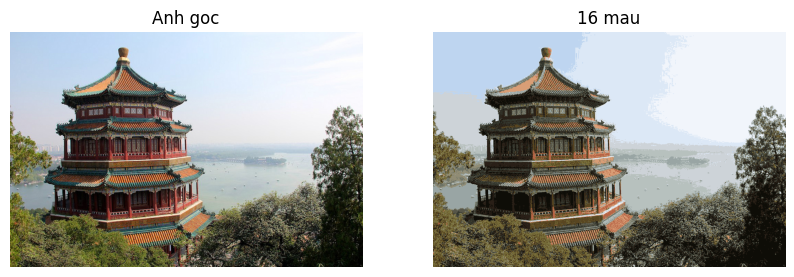

In [12]:
import os
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

def nen_anh(anh, k=16):
    """anh: mang (cao, rong, 3) dang uint8 hoac float 0-1. Tra ve (anh nen, anh goc 3 kenh), float 0-1."""
    if anh.dtype == np.uint8:
        anh = anh / 255.0
    anh = anh[:, :, :3]                                # bo kenh trong suot neu co
    cao, rong, _ = anh.shape
    diem = anh.reshape(-1, 3)
    rng = np.random.default_rng(0)
    mau = diem[rng.choice(len(diem), min(5000, len(diem)), replace=False)]
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    return km.cluster_centers_[km.predict(diem)].reshape(cao, rong, 3), anh

def luu(anh, ten_goc, ten_nen):
    anh_moi, anh3 = nen_anh(anh)
    plt.imsave(ten_goc, anh3)
    plt.imsave(ten_nen, np.clip(anh_moi, 0, 1))
    a, b = os.path.getsize(ten_goc), os.path.getsize(ten_nen)
    print(f"{ten_goc}: {a/1024:.1f} KB | {ten_nen}: {b/1024:.1f} KB | nho hon {a/b:.2f} lan")
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(anh3); ax[0].set_title("Anh goc"); ax[0].axis("off")
    ax[1].imshow(np.clip(anh_moi, 0, 1)); ax[1].set_title("16 mau"); ax[1].axis("off")
    plt.show()

luu(load_sample_image("china.jpg"), "china_goc.png", "anh_16_mau.png")

BÀi 5

In [13]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans

tr = pd.read_csv("data/hai_vang_trang.csv")
X, that = tr[["x1", "x2"]].to_numpy(), tr["nhan"].to_numpy()

def khop(nhan):
    k = (nhan == that).mean()
    return max(k, 1 - k)

print(f"K-Means K=2: khop nhan that {khop(KMeans(2, n_init=10, random_state=0).fit_predict(X)):.4f}")
for e in [0.2, 0.3, 0.4]:
    nhan = DBSCAN(eps=e, min_samples=5).fit_predict(X)
    so_cum = len(set(nhan)) - (1 if -1 in nhan else 0)
    nhieu = int((nhan == -1).sum())
    print(f"eps = {e}: {so_cum} cum, {nhieu} diem nhieu")

K-Means K=2: khop nhan that 0.7500
eps = 0.2: 1 cum, 40 diem nhieu
eps = 0.3: 1 cum, 10 diem nhieu
eps = 0.4: 1 cum, 3 diem nhieu


BÀi 6

In [14]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_digits

X, y = load_digits(return_X_y=True)
cum = KMeans(n_clusters=10, n_init=10, random_state=0).fit_predict(X)
bang = pd.crosstab(pd.Series(y, name="chu so that"), pd.Series(cum, name="cum"))
print(bang.to_string())
print("\nCum chiem nhieu nhat cua tung chu so (ty le chu so do nam trong cum do):")
for d in range(10):
    hang = bang.loc[d]
    print(f"  chu so {d}: cum {hang.idxmax()}, {hang.max()/hang.sum():.2f}")

cum            0    1    2   3    4    5    6    7    8    9
chu so that                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0

Cum chiem nhieu nhat cua tung chu so (ty le chu so do nam trong cum do):
  chu so 0: cum 0, 0.99
  chu so 1: cum 1, 0.55
  chu so 2: cum 9, 0.84
  chu so 3: cum 4, 0.84
  chu so 4: cum 6, 0.91
  chu so 5: cum 7, 0.75
  chu so 6: cum 5, 0.98
  chu so 7: cum 2, 0.97
  